# How Gradient Variance Shapes Policy Optimization

<div style="display:flex; gap:16px; align-items:center; justify-content:center;">
    <img src="_images/bandit_octopus.png" alt="Ten-armed bandit illustration" style="width:40%; height:auto;"/>
</div>

In this article, we'll investigate how reward baselines affect the learning dynamics of policy-gradient algorithms using a simple multi-armed bandit problem. Unlike value-based methods, which estimate the expected reward associated with each action, policy-gradient methods directly optimize the probabilities with which actions are selected.

Our objective is to maximize the expected reward under a parameterized policy:

$$
J(\theta)=\mathbb{E}_{\pi_\theta}[R]
$$

Here, $\theta$ denotes the policy parameters. We can optimize this objective using gradient ascent:

$$
\theta_{t+1}=\theta_t+\alpha\nabla_\theta J(\theta_t)
$$

where $\alpha$ is the learning rate. However, since the reward distributions are unknown, we cannot calculate this gradient directly. Instead, we can use the log-derivative identity to estimate it from sampled actions and rewards.

For a multi-armed bandit, we can write the objective as:

$$
J(\theta)=\sum_a\pi_\theta(a)q_*(a)
$$

where $q_*(a)$ is the true expected reward for action $a$. Taking the gradient:

$$
\begin{aligned}
\nabla_\theta J(\theta)
&=\sum_a q_*(a)\nabla_\theta\pi_\theta(a)\\
&=\sum_a\pi_\theta(a)q_*(a)\nabla_\theta\log\pi_\theta(a)\\
&=\mathbb{E}_{\pi_\theta}\left[R\nabla_\theta\log\pi_\theta(A)\right]
\end{aligned}
$$

This gives us an unbiased estimate of the policy gradient using a single sampled action and reward. The resulting update is:

$$
\theta_{t+1}=\theta_t+\alpha R_t\nabla_\theta\log\pi_{\theta_t}(A_t)
$$

## Gradient Bandits

For our experiments, we'll use a gradient-bandit agent. It maintains a preference $H_t(a)$ for each action rather than an estimate of its expected reward. These preferences determine the action probabilities through a softmax policy:

$$
\pi_t(a)=\frac{\exp(H_t(a))}{\sum_b\exp(H_t(b))}
$$

The derivative of the log-probability of the selected action with respect to each preference is:

$$
\frac{\partial\log\pi_t(A_t)}{\partial H_t(a)}
=\mathbb{1}[a=A_t]-\pi_t(a)
$$

where $\mathbb{1}[a=A_t]$ is 1 if $a$ was selected and 0 otherwise. Substituting this into our gradient update gives:

$$
H_{t+1}(a)=H_t(a)+\alpha R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

A positive reward increases the preference for the selected action and decreases the preferences for the others. A negative reward has the opposite effect.

Let's begin by implementing a $k$-armed bandit environment. Each action produces rewards with unit variance and a fixed expected value $q_*(a)$, sampled independently from:

$$
q_*(a)\sim\mathcal N(\mu,1)
$$

We'll vary $\mu$ to shift all the expected rewards by the same amount. Since this does not change the differences between action values or which action is optimal, it gives us a useful way to investigate whether the absolute magnitude of rewards affects learning.

In [1]:
from typing import NamedTuple
import jax
import jax.numpy as jnp


class KArmedBandit:
    def __init__(self, k=10, mean=0.0):
        self.k = k
        self.mean = mean

    def reset(self, key):
        q_star = self.mean + jax.random.normal(key, shape=(self.k,))
        observation = 0
        env_state = q_star
        return env_state, observation

    def step(self, key, env_state, action):
        reward = env_state[action] + jax.random.normal(key) 
        observation = 0
        terminated = False

        info = {}

        return env_state, observation, reward, terminated, info


Next, we'll implement the gradient-bandit agent using the softmax policy and preference update derived above.

In [2]:


class GradientBanditState(NamedTuple):
    H: jax.Array
    N: jax.Array


class GradientBanditAgent:
    def __init__(self, k=10, alpha=0.1):
        self.k = k
        self.alpha = alpha
        

    def init(self):
        # Initialize action preferences H to zeros
        return GradientBanditState(
                H=jnp.zeros(self.k),
                N=jnp.array(0, dtype=jnp.int32)
        )

    def select_action(self, key, agent_state: GradientBanditState):
        # Sample an action from softmax(H)
        H,  _ = agent_state
        probs = jax.nn.softmax(H)
        action = jax.random.choice(key, a=self.k, p=probs)
        return action

    def update(self, agent_state, action, reward):
        H, N = agent_state
        probs = jax.nn.softmax(H)
        mask = jnp.zeros(self.k).at[action].set(1)
        H = H + self.alpha * (reward) * (mask - probs)
        return GradientBanditState(
            H=H,
            N=N+1
        )

Let's train the agent with reward offsets of $0$, $2$, $4$, and $8$. For each offset, we'll run 2,000 independent bandit problems for 1,000 training steps each.

In [3]:
k = 10
num_runs = 2000
num_steps = 1000

means = [0.0, 2.0, 4.0, 8.0]

agent = GradientBanditAgent(
    k=k,
    alpha=0.1,
)

env = KArmedBandit(k=k, mean=0.0)

def run_experiment(key, reward_offset):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        log_probs = jax.nn.log_softmax(agent_state.H)
        probs = jnp.exp(log_probs)
        entropy = -jnp.sum(probs * log_probs)

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        reward = reward + reward_offset

        agent_state = agent.update(
            agent_state, action, reward
        )

        is_optimal = action == optimal_action

        return (
            key, agent_state, env_state
        ), (is_optimal, entropy)

    initial_carry = (key, agent_state, env_state)

    _, (optimal_actions, entropies) = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return optimal_actions, entropies


key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

means = jnp.array([0.0, 2.0, 4.0, 8.0])

batched_experiment = jax.jit(
    jax.vmap(
        jax.vmap(run_experiment, in_axes=(0, None)),
        in_axes=(None, 0),
    )
)

optimal_actions, entropies = batched_experiment(keys, means)

mean_optimal = 100 * jnp.mean(optimal_actions, axis=1)
mean_entropy = jnp.mean(entropies, axis=1)


First, let's plot how often the agent selects the optimal action at each training step, averaged across the 2,000 runs.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/696917459.py:34: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


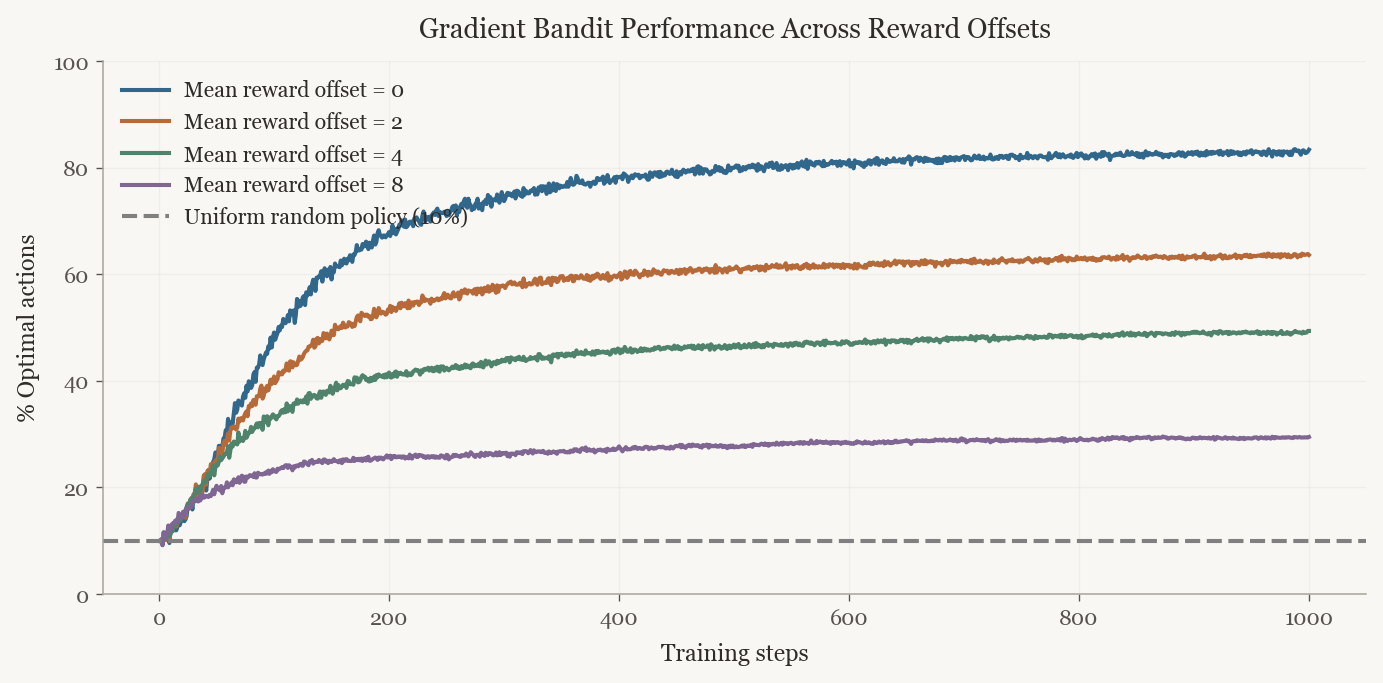

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.style.use('../mplstyle/blog.mplstyle')

plt.figure(figsize=(10, 5))

results = {
    float(mean): mean_optimal[i]
    for i, mean in enumerate(means)
}

steps = jnp.arange(1, num_steps + 1)

for mean, percentages in results.items():
    plt.plot(
        steps,
        percentages,
        label=f"Mean reward offset = {mean:.0f}",
    )

plt.axhline(
    y=100 / k,
    color="gray",
    linestyle="--",
    label="Uniform random policy (10%)",
)

plt.xlabel("Training steps")
plt.ylabel("% Optimal actions")
plt.title("Gradient Bandit Performance Across Reward Offsets")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


We can observe that performance deteriorates as the reward offset increases. This is surprising because shifting every action's expected reward by the same constant does not change the optimal action or the expected policy gradient. Let's examine the distribution of optimal-action frequencies across individual runs to see where this difference comes from.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/1135208797.py:42: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


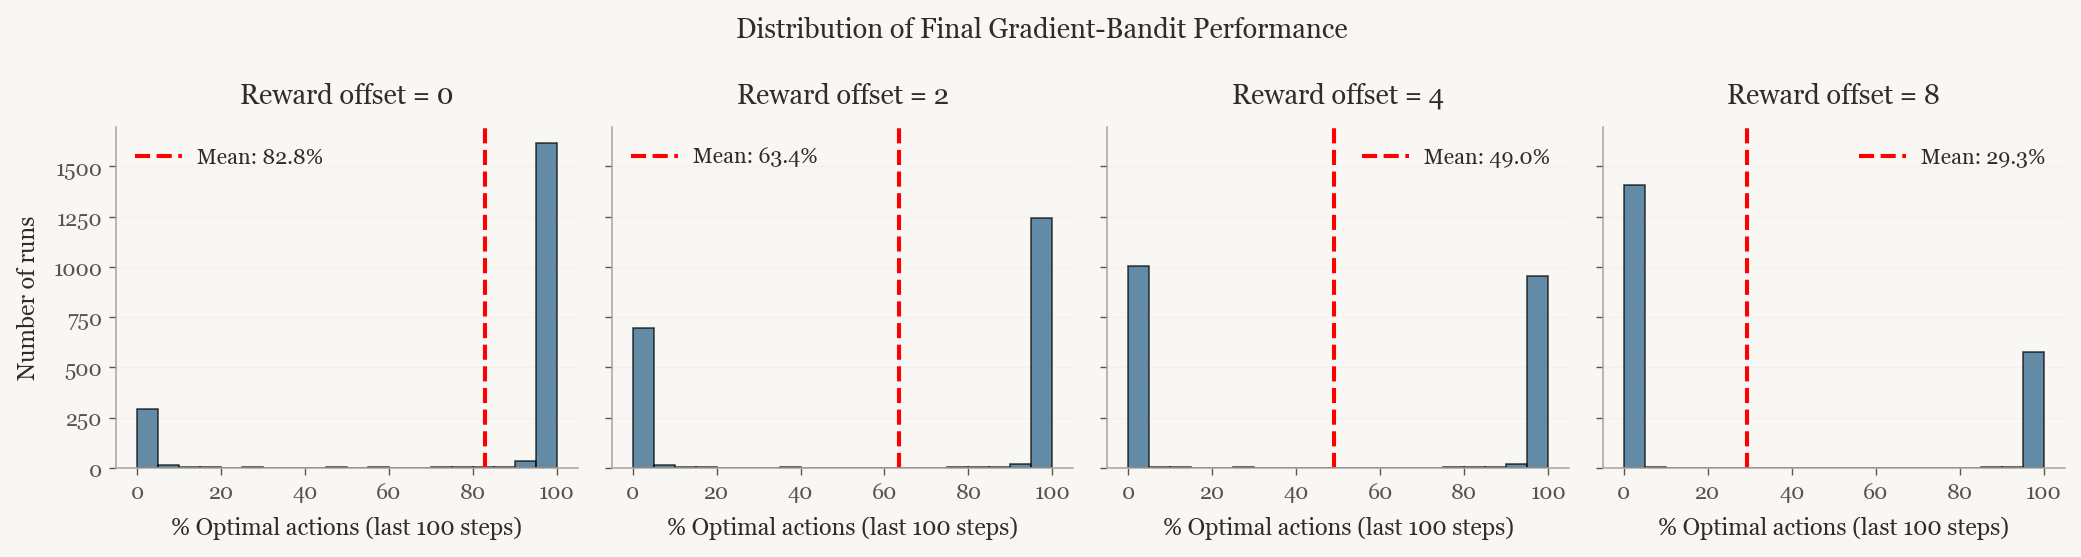

In [5]:
import numpy as np

final_optimal_pct = (
    100 * jnp.mean(optimal_actions[:, :, -100:], axis=2)
)

fig, axes = plt.subplots(
    1, 4, figsize=(15, 4), sharex=True, sharey=True
)

bins = np.arange(0, 105, 5)

for i, (ax, mean) in enumerate(zip(axes, means)):
    final_performance = np.asarray(final_optimal_pct[i])

    ax.hist(
        final_performance,
        bins=bins,
        edgecolor="black",
        alpha=0.75,
    )

    ax.axvline(
        final_performance.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {final_performance.mean():.1f}%",
    )

    ax.set_title(f"Reward offset = {float(mean):.0f}")
    ax.set_xlabel("% Optimal actions (last 100 steps)")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Number of runs")

fig.suptitle(
    "Distribution of Final Gradient-Bandit Performance",
    fontsize=14,
)

plt.tight_layout()
plt.show()


The distributions are strongly bimodal. Most runs either select the optimal action almost all the time or rarely select it at all. As the reward offset increases, a larger proportion of runs end up in the second group.

One possible explanation is that large preference updates cause the policy to concentrate on an action too early, sometimes before it has identified the optimal one. We can investigate this by measuring policy entropy.

### Measuring Policy Entropy

Policy entropy measures how spread out the action-selection probabilities are. For a policy $\pi_t$, it is defined as:

$$
\mathcal H(\pi_t)=-\sum_a\pi_t(a)\log\pi_t(a)
$$

Entropy is highest when all actions are equally likely. For our 10-armed bandit, the maximum is:

$$
\mathcal H_{\max}=\log(10)\approx2.303
$$

As the policy concentrates on a single action, its entropy approaches zero. Note that low entropy does not necessarily mean the policy has learned the optimal action. It only tells us that the policy strongly favors a particular action.

We'll calculate entropy from the softmax probabilities at every training step and average it across runs.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/2075688572.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


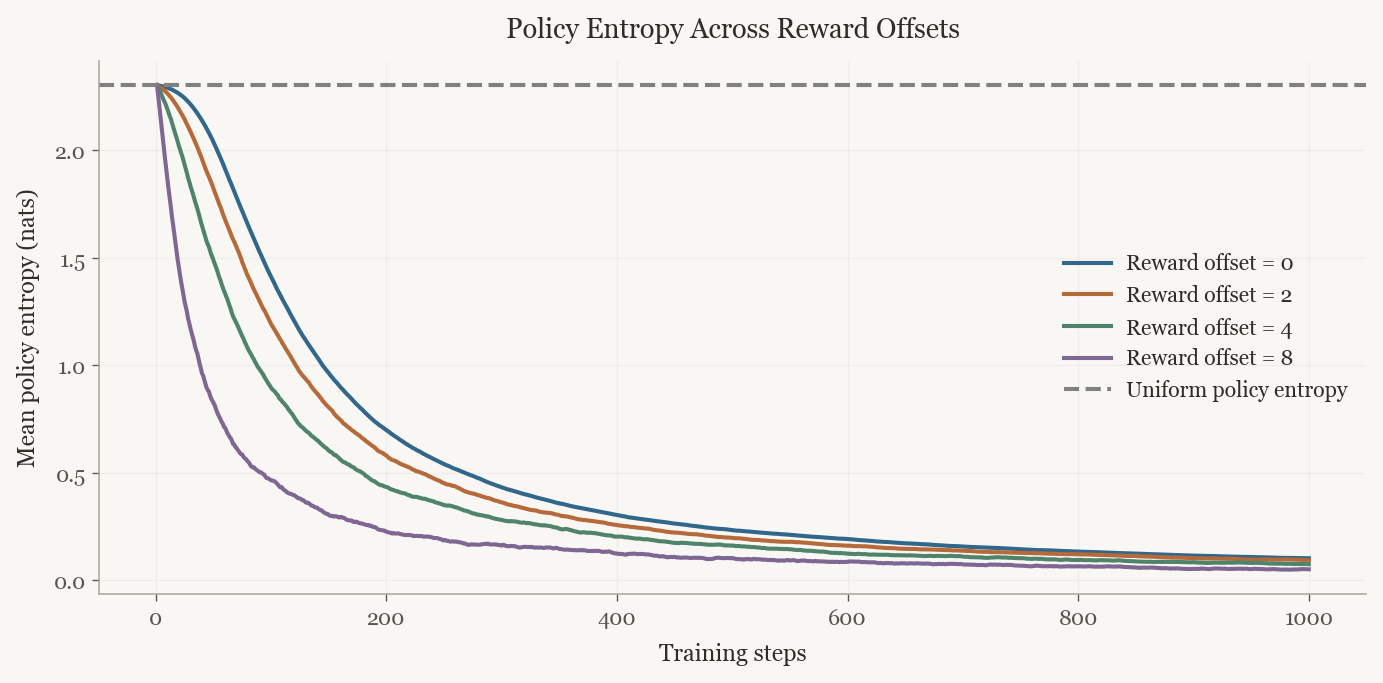

In [6]:
plt.figure(figsize=(10, 5))

steps = jnp.arange(1, num_steps + 1)

for i, mean in enumerate(means):
    plt.plot(
        steps,
        mean_entropy[i],
        label=f"Reward offset = {float(mean):.0f}",
    )

plt.axhline(
    y=float(jnp.log(k)),
    color="gray",
    linestyle="--",
    label="Uniform policy entropy",
)

plt.xlabel("Training steps")
plt.ylabel("Mean policy entropy (nats)")
plt.title("Policy Entropy Across Reward Offsets")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


We can observe that entropy decreases much faster for larger reward offsets. The agent is becoming increasingly confident in one action, even though its probability of selecting the optimal action is falling.

A possible explanation is that larger rewards increase the variance of the stochastic gradient estimates. Let's measure this directly.

### Measuring Gradient Variance

Recall the preference update:

$$
H_{t+1}(a)=H_t(a)+\alpha R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

The stochastic gradient estimate for preference $H_t(a)$ is therefore:

$$
\hat g_t(a)=R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

Since the gradient has one component for every action, we'll measure its total variance by summing the variance of each component:

$$
V=\sum_a\mathbb{E}\left[\left(\hat g_t(a)-\mathbb{E}[\hat g_t(a)]\right)^2\right]
$$

For this experiment, we'll hold the policy fixed at the uniform distribution and sample independent actions and rewards. Unlike the previous experiments, the agent will not update its preferences. This allows us to isolate the effect of the reward offset without introducing changes in the policy itself.

In [7]:

k = 10
num_samples = 100_000
reward_offsets = jnp.array([0.0, 2.0, 4.0, 8.0])

key = jax.random.key(123)
key, values_key, actions_key, noise_key = jax.random.split(key, 4)

# Fix one bandit problem, with q*(a) ~ N(0, 1)
q_star = jax.random.normal(values_key, (k,))

# Fix a uniform policy throughout the experiment
probs = jnp.ones(k) / k

# Same actions and reward noise for all offsets
actions = jax.random.choice(
    actions_key, k, shape=(num_samples,), p=probs
)
noise = jax.random.normal(noise_key, (num_samples,))

# Score function: grad_H log pi(A)
scores = jax.nn.one_hot(actions, k) - probs

def gradient_variance(gradients):
    mean_gradient = jnp.mean(gradients, axis=0)
    centered = gradients - mean_gradient
    return jnp.mean(jnp.sum(centered ** 2, axis=1))

variances = []

for offset in reward_offsets:
    rewards = q_star[actions] + noise + offset
    gradients = rewards[:, None] * scores
    variances.append(gradient_variance(gradients))

variances = jnp.stack(variances)

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/132038405.py:15: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


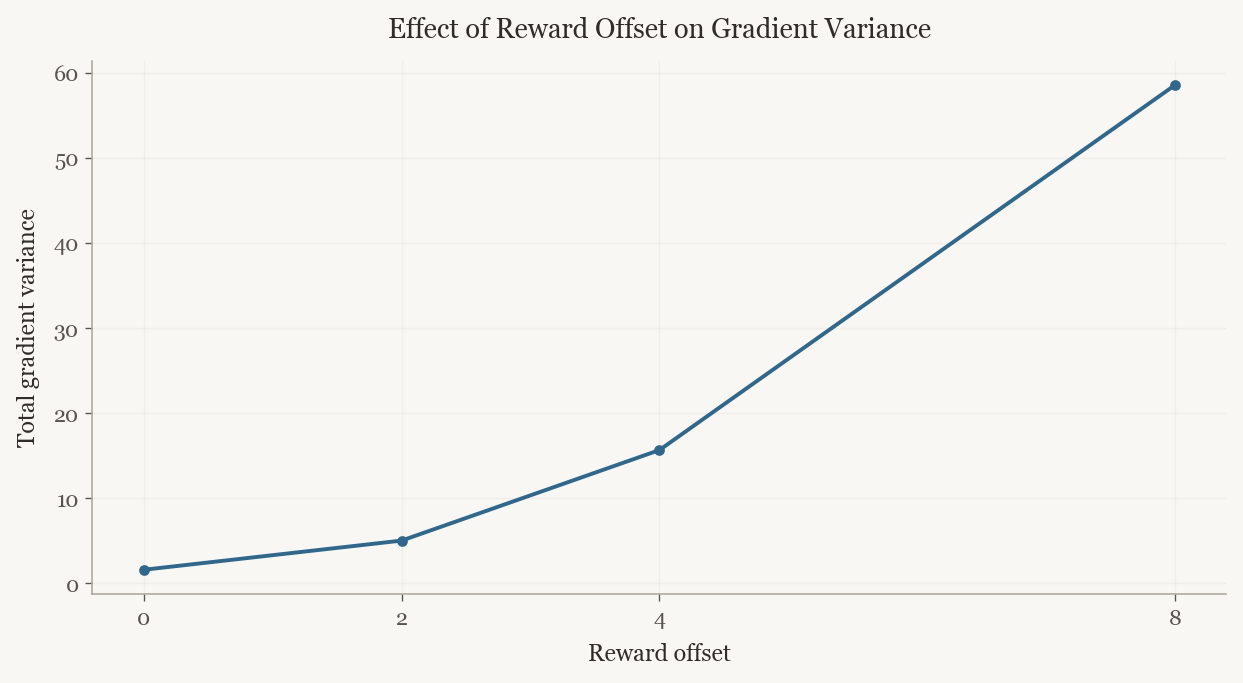

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.asarray(reward_offsets),
    np.asarray(variances),
    "o-",
    linewidth=2,
)

plt.xlabel("Reward offset")
plt.ylabel("Total gradient variance")
plt.title("Effect of Reward Offset on Gradient Variance")
plt.xticks(np.asarray(reward_offsets))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


We can see that gradient variance increases rapidly as the reward offset grows. The relationship is approximately quadratic, even though the expected gradient and the differences between action values remain unchanged.

This helps explain our earlier results. Large reward offsets produce noisier preference updates, which may cause the policy to concentrate on an action before it has explored the alternatives sufficiently. Can we reduce this variance without changing the expected policy gradient?

A simple way to do this is to subtract a reward baseline.

## Introducing a Reward Baseline

Our current preference update is:

$$
H_{t+1}(a)=H_t(a)+\alpha R_t\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

When rewards are large and positive, even a suboptimal action can receive a large positive preference update whenever it is selected. Instead of using the absolute reward, we can subtract a reference value $b_t$:

$$
H_{t+1}(a)=H_t(a)+\alpha(R_t-b_t)\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

We'll use the average reward observed before the current step as our baseline:

$$
b_t=\bar R_t=\frac{1}{t-1}\sum_{i=1}^{t-1}R_i
$$

For the first step, we'll initialize the baseline to zero. We can then update the running average incrementally:

$$
\bar R_{t+1}=\bar R_t+\frac{1}{t}(R_t-\bar R_t)
$$

Notice that the preference update uses the previous average, before incorporating the current reward. This means an action's preference changes according to whether its reward is above or below the historical average, rather than according to the absolute reward.

### Why Doesn't a Baseline Change the Expected Policy Gradient?

Recall that our objective is:

$$
J(\theta)=\mathbb{E}_{\pi_\theta}[R]
$$

Using the log-derivative identity, we obtained:

$$
\nabla_\theta J(\theta)=\mathbb{E}_{\pi_\theta}\left[R\nabla_\theta\log\pi_\theta(A)\right]
$$

Now consider subtracting a baseline $b$ that does not depend on the sampled action:

$$
\mathbb{E}_{\pi_\theta}\left[(R-b)\nabla_\theta\log\pi_\theta(A)\right]
$$

Expanding this expression gives:

$$
\mathbb{E}_{\pi_\theta}\left[R\nabla_\theta\log\pi_\theta(A)\right]
-b\mathbb{E}_{\pi_\theta}\left[\nabla_\theta\log\pi_\theta(A)\right]
$$

The second term is zero. To see why, recall that:

$$
\nabla_\theta\log\pi_\theta(a)=\frac{\nabla_\theta\pi_\theta(a)}{\pi_\theta(a)}
$$

Therefore:

$$
\begin{aligned}
\mathbb{E}_{\pi_\theta}\left[\nabla_\theta\log\pi_\theta(A)\right]
&=\sum_a\pi_\theta(a)\nabla_\theta\log\pi_\theta(a)\\
&=\sum_a\nabla_\theta\pi_\theta(a)\\
&=\nabla_\theta\sum_a\pi_\theta(a)\\
&=\nabla_\theta 1\\
&=0
\end{aligned}
$$

Consequently, subtracting an action-independent baseline leaves the expected gradient unchanged. This also applies to our running-average baseline because it only uses rewards observed before the current action is sampled.

The two estimators therefore have the same expected value at a fixed policy, although their variances can be very different.

## Does the Baseline Help?

Let's modify our gradient-bandit agent to maintain a running average reward and use it as a baseline in the preference update.

In [9]:
class GradientBanditState(NamedTuple):
    H: jax.Array
    avg_reward: jax.Array
    N: jax.Array


class GradientBanditAgent:
    def __init__(self, k=10, alpha=0.1, use_baseline=True):
        self.k = k
        self.alpha = alpha
        self.use_baseline = use_baseline
        

    def init(self):
        # Initialize action preferences H to zeros
        return GradientBanditState(
                H=jnp.zeros(self.k),
                avg_reward=jnp.array(0.0),
                N=jnp.array(0, dtype=jnp.int32)
        )

    def select_action(self, key, agent_state: GradientBanditState):
        # Sample an action from softmax(H)
        H, _, _ = agent_state
        probs = jax.nn.softmax(H)
        action = jax.random.choice(key, a=self.k, p=probs)
        return action

    def update(self, agent_state, action, reward):
        H, avg_reward, N = agent_state
        probs = jax.nn.softmax(H)
        mask = jnp.zeros(self.k).at[action].set(1)
        baseline = avg_reward if self.use_baseline else 0.0
        H = H + self.alpha * (reward - avg_reward) * (mask - probs)
        avg_reward = avg_reward + (reward - baseline) / (N + 1)
        return GradientBanditState(
            H=H,
            avg_reward=avg_reward,
            N=N+1
        )

We'll compare agents with and without a baseline on bandit problems with a reward offset of $4$. As before, we'll measure the frequency with which each agent selects the optimal action during training.

In [10]:

# Same environment and experimental configuration
env = KArmedBandit(k=10, mean=4.0)

configurations = {
    "Without baseline": GradientBanditAgent(
        k=10, alpha=0.1, use_baseline=False
    ),
    "With baseline": GradientBanditAgent(
        k=10, alpha=0.1, use_baseline=True
    ),
}


def run_experiment(key, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        agent_state = agent.update(
            agent_state, action, reward
        )

        is_optimal = action == optimal_action

        return (key, agent_state, env_state), is_optimal

    initial_carry = (key, agent_state, env_state)

    _, optimal_actions = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return optimal_actions


key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for name, agent in configurations.items():
    batched_experiment = jax.jit(
        jax.vmap(lambda run_key: run_experiment(run_key, agent))
    )

    optimal_actions = batched_experiment(keys)
    results[name] = 100 * jnp.mean(optimal_actions, axis=0)


/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/772520547.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


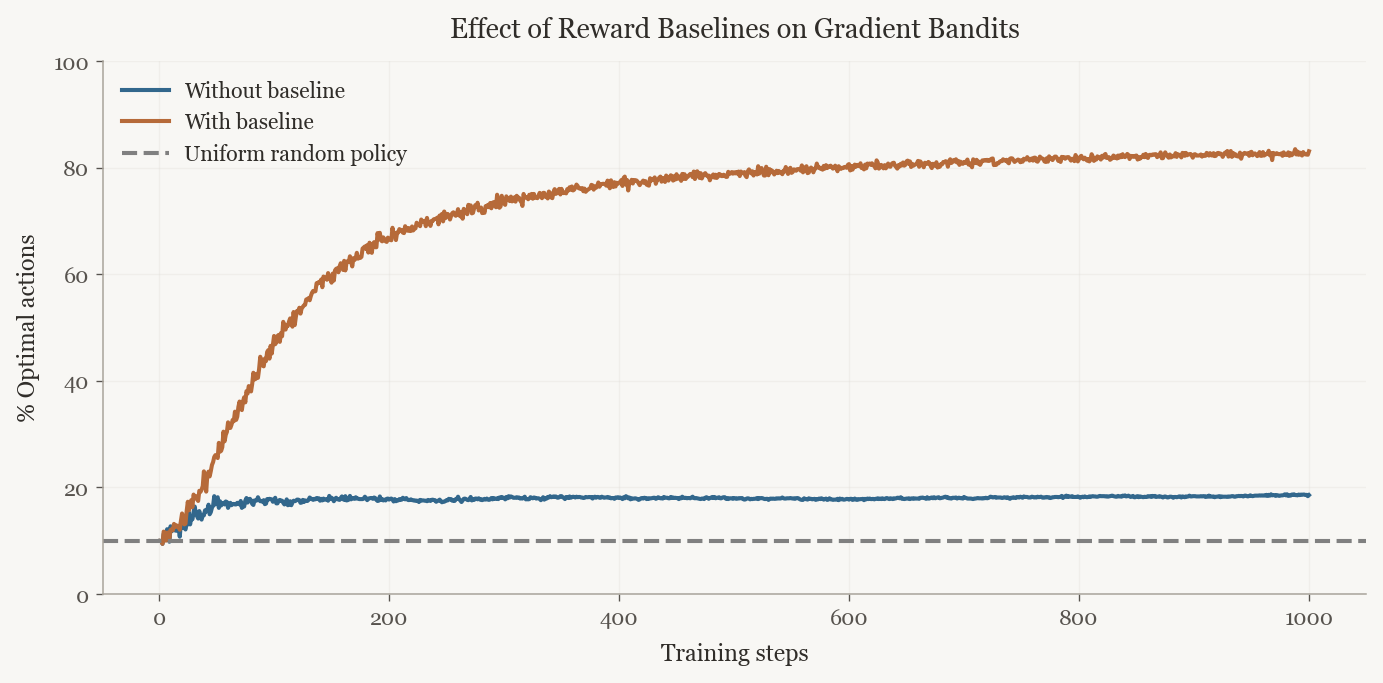

In [11]:
plt.figure(figsize=(10, 5))

steps = jnp.arange(1, num_steps + 1)

for name, percentages in results.items():
    plt.plot(steps, percentages, label=name)

plt.axhline(
    100 / k,
    color="gray",
    linestyle="--",
    label="Uniform random policy",
)

plt.xlabel("Training steps")
plt.ylabel("% Optimal actions")
plt.title("Effect of Reward Baselines on Gradient Bandits")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The agent using a reward baseline selects the optimal action considerably more often. Let's check whether this improvement persists across different reward offsets.

## Looking Across Reward Offsets

We'll repeat the comparison with offsets of $0$, $2$, $4$, and $8$, keeping the training configuration unchanged.

In [12]:
k = 10
num_runs = 2000
num_steps = 1000
alpha = 0.1

reward_means = [0.0, 2.0, 4.0, 8.0]


def run_experiment(key, env, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        action = agent.select_action(action_key, agent_state)

        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        agent_state = agent.update(
            agent_state, action, reward
        )

        return (key, agent_state, env_state), action

    initial_carry = (key, agent_state, env_state)

    _, actions = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    optimal_action = jnp.argmax(env_state)

    # Percentage of optimal actions in final 100 steps
    final_optimal_pct = 100 * jnp.mean(
        actions[-100:] == optimal_action
    )

    return final_optimal_pct

In [13]:
key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for mu in reward_means:
    env = KArmedBandit(k=k, mean=mu)

    for use_baseline in [True, False]:
        agent = GradientBanditAgent(
            k=k,
            alpha=alpha,
            use_baseline=use_baseline,
        )

        batched_experiment = jax.jit(
            jax.vmap(
                lambda run_key: run_experiment(
                    run_key, env, agent
                )
            )
        )

        final_pct = batched_experiment(keys)

        results[(mu, use_baseline)] = np.asarray(final_pct)


/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/74129231.py:34: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


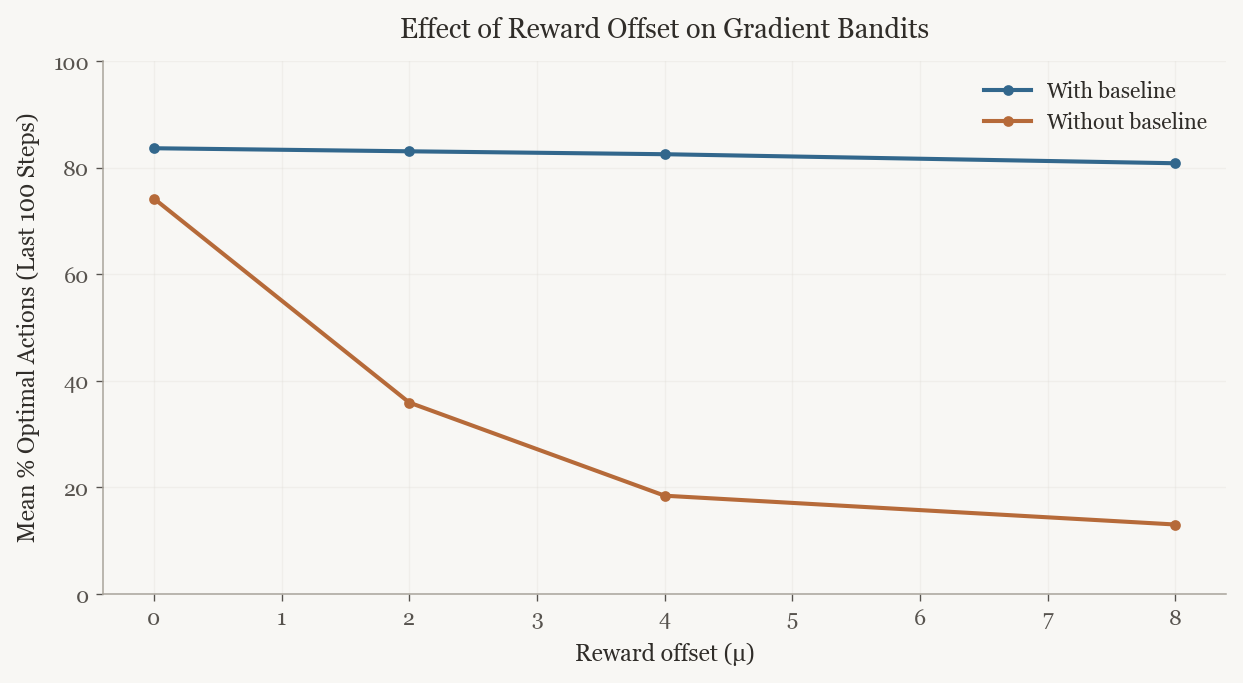

In [14]:
means_with = []
means_without = []

for mu in reward_means:
    means_with.append(
        np.mean(results[(mu, True)])
    )
    means_without.append(
        np.mean(results[(mu, False)])
    )

plt.figure(figsize=(9, 5))

plt.plot(
    reward_means,
    means_with,
    marker="o",
    label="With baseline",
)

plt.plot(
    reward_means,
    means_without,
    marker="o",
    label="Without baseline",
)

plt.xlabel("Reward offset (μ)")
plt.ylabel("Mean % Optimal Actions (Last 100 Steps)")
plt.title("Effect of Reward Offset on Gradient Bandits")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The baseline agent maintains fairly consistent performance as the reward offset increases. In contrast, the agent without a baseline becomes progressively worse. Let's examine the final optimal-action frequencies across individual runs rather than looking only at their averages.

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/1593458216.py:43: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


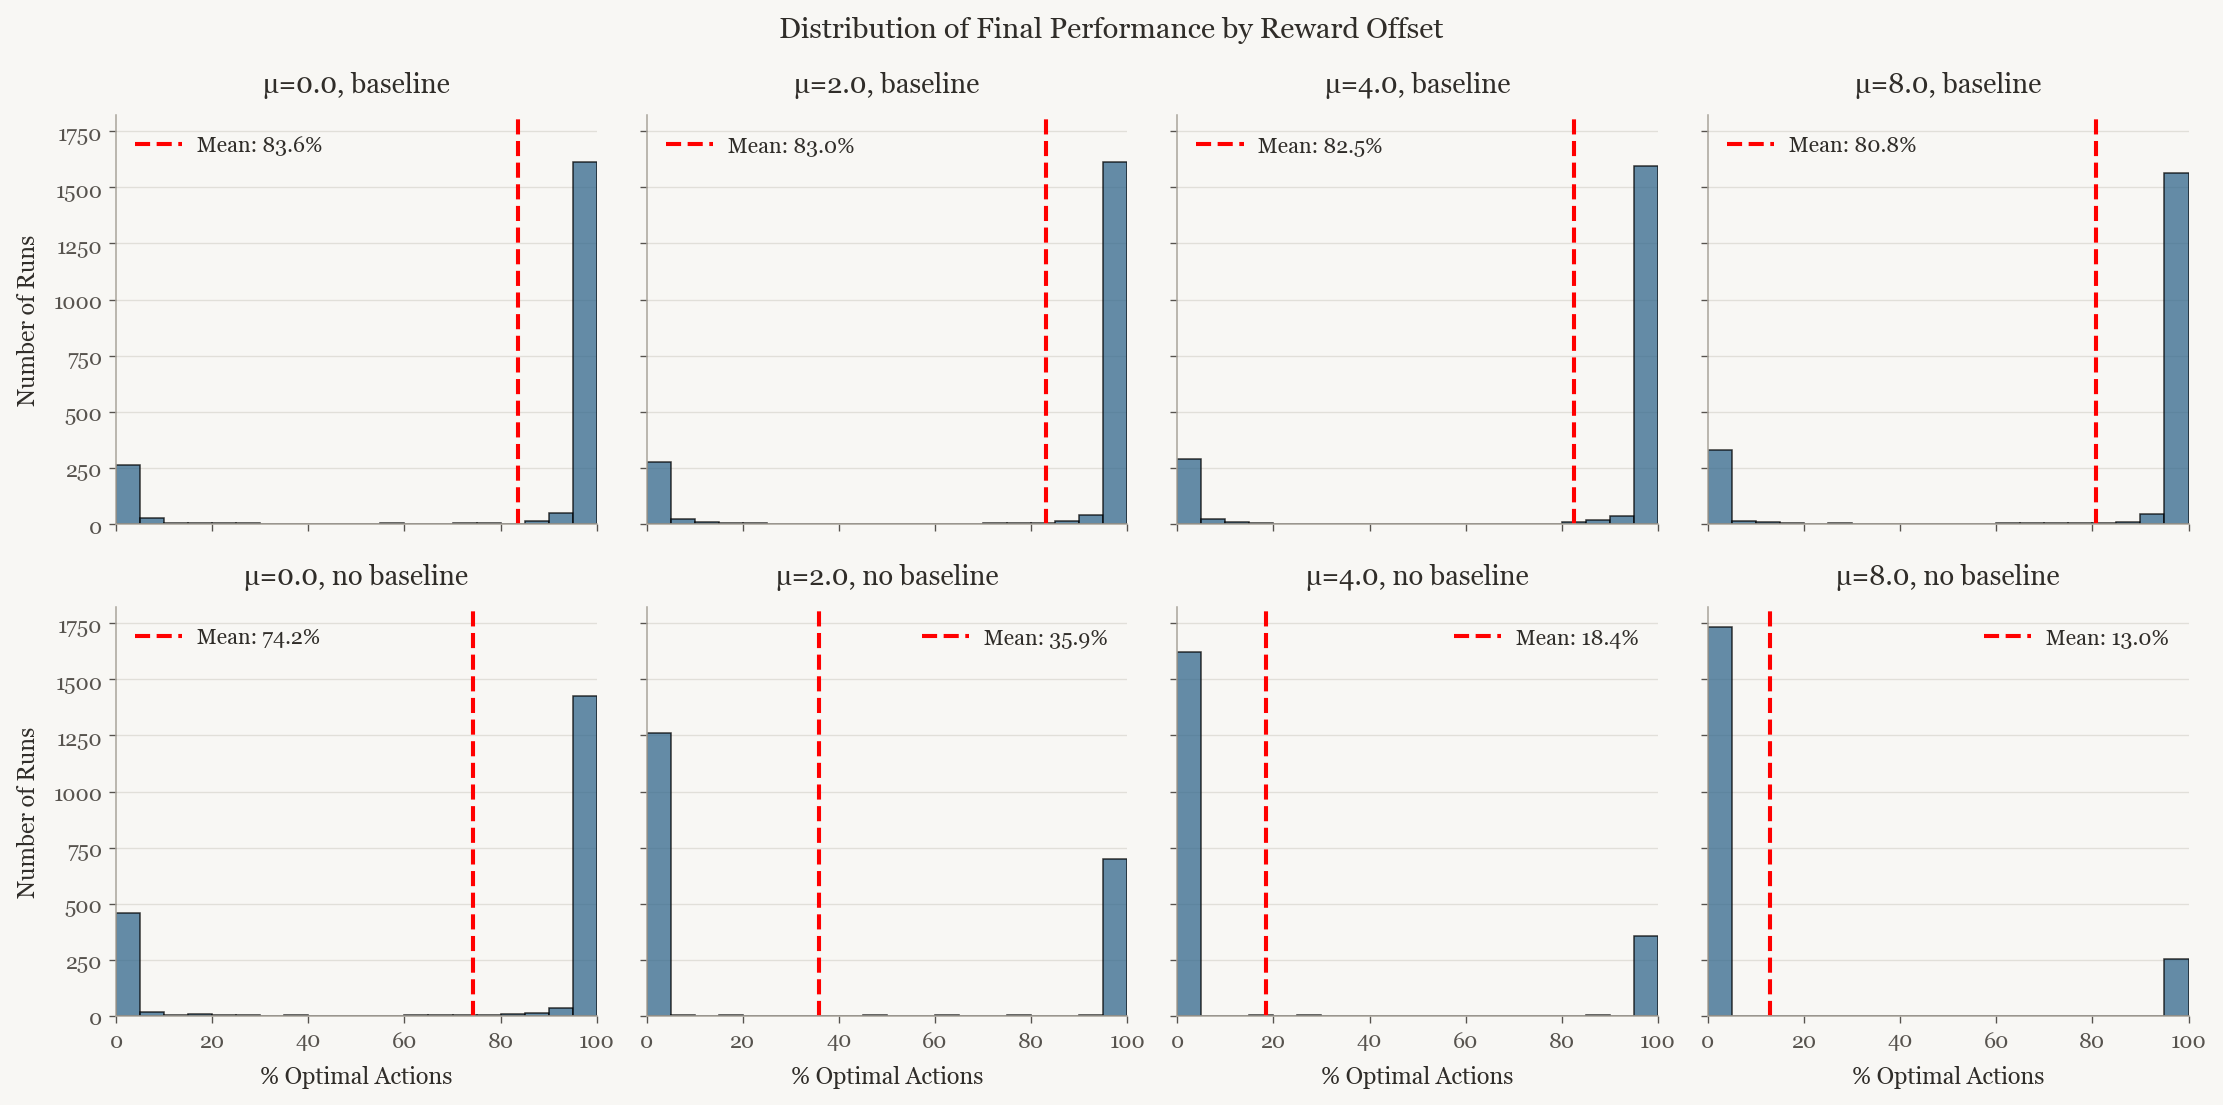

In [15]:
fig, axes = plt.subplots(
    2, 4, figsize=(16, 8),
    sharex=True,
    sharey=True,
)

bins = np.linspace(0, 100, 21)

for col, mu in enumerate(reward_means):
    for row, use_baseline in enumerate([True, False]):
        ax = axes[row, col]
        data = results[(mu, use_baseline)]

        ax.hist(
            data,
            bins=bins,
            edgecolor="black",
            alpha=0.75,
        )

        ax.axvline(
            np.mean(data),
            color="red",
            linestyle="--",
            label=f"Mean: {np.mean(data):.1f}%",
        )

        ax.set_title(
            f"μ={mu}, "
            f"{'baseline' if use_baseline else 'no baseline'}"
        )
        ax.set_xlim(0, 100)
        ax.legend()

        if row == 1:
            ax.set_xlabel("% Optimal Actions")
        if col == 0:
            ax.set_ylabel("Number of Runs")

fig.suptitle(
    "Distribution of Final Performance by Reward Offset"
)
plt.tight_layout()
plt.show()


The distribution of optimal-action frequencies remains relatively stable with a baseline. Without one, it shifts sharply toward zero as the reward offset increases. At $\mu=8$, most runs rarely select the optimal action during the final 100 steps.

Next, let's compare the variance of the gradient estimates with and without a baseline, using the same reward offsets.

In [16]:
# Configuration
k = 10
num_samples = 100_000
reward_means = [0.0, 2.0, 4.0, 8.0]

key = jax.random.key(42)

# Fix a single bandit problem
key, env_key = jax.random.split(key)
q_base = jax.random.normal(env_key, shape=(k,))

# Fix the policy: all preferences initially zero
H = jnp.zeros(k)
probs = jax.nn.softmax(H)

# Generate shared action and reward randomness
key, action_key, noise_key = jax.random.split(key, 3)

actions = jax.random.choice(
    action_key,
    a=k,
    shape=(num_samples,),
    p=probs,
)

noise = jax.random.normal(noise_key, (num_samples,))

# Score-function gradients: ∇ log π(A)
one_hot = jax.nn.one_hot(actions, k)
score_gradients = one_hot - probs


def measure_gradient_variance(mu, use_baseline):
    # Same underlying action values, shifted by mu
    q_star = q_base + mu

    # Observed rewards
    rewards = q_star[actions] + noise

    # Exact expected reward under the fixed policy
    baseline = jnp.dot(probs, q_star) if use_baseline else 0.0

    # Stochastic gradient estimates
    gradients = (
        (rewards - baseline)[:, None] * score_gradients
    )

    # Mean gradient
    mean_gradient = jnp.mean(gradients, axis=0)

    # Total variance: sum of component variances
    total_variance = jnp.sum(
        jnp.var(gradients, axis=0)
    )

    return float(total_variance), np.asarray(mean_gradient)

In [17]:
results = {
    "With baseline": [],
    "Without baseline": [],
}

for mu in reward_means:
    for use_baseline in [True, False]:
        variance, mean_grad = measure_gradient_variance(
            mu, use_baseline
        )

        name = (
            "With baseline"
            if use_baseline
            else "Without baseline"
        )

        results[name].append(variance)

/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/673521976.py:17: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


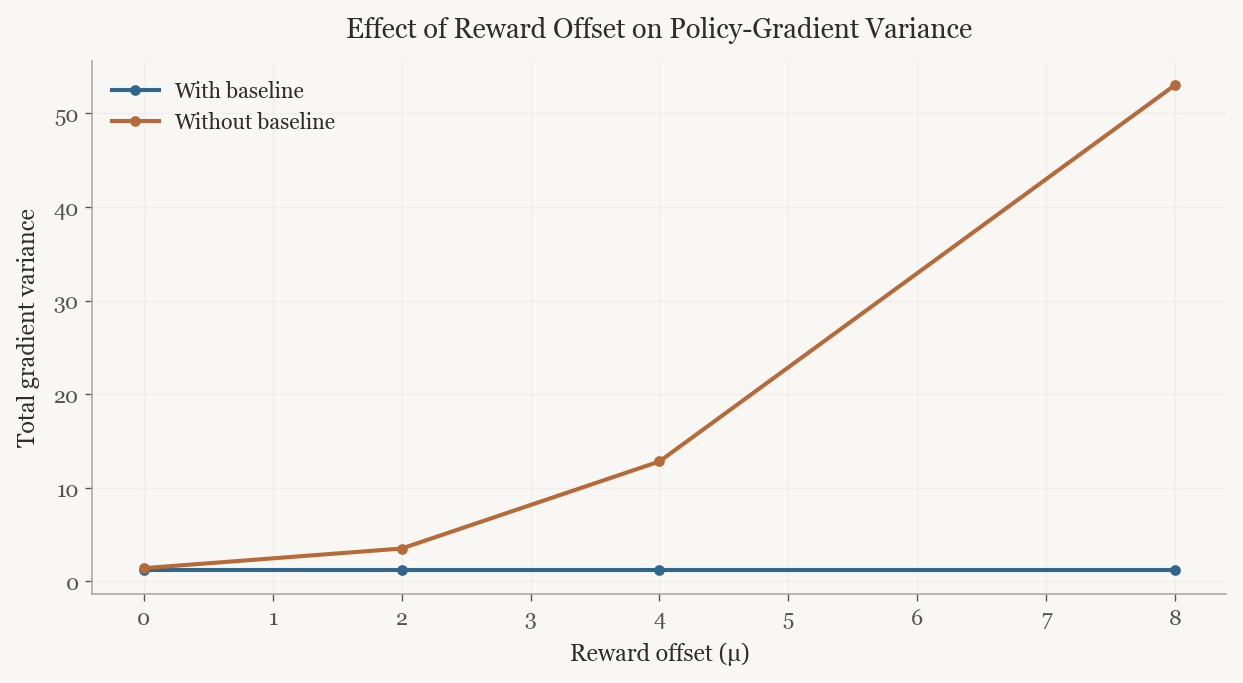

In [18]:
# Plot gradient variance
plt.figure(figsize=(9, 5))

for name, variances in results.items():
    plt.plot(
        reward_means,
        variances,
        marker="o",
        label=name,
    )

plt.xlabel("Reward offset (μ)")
plt.ylabel("Total gradient variance")
plt.title("Effect of Reward Offset on Policy-Gradient Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


We can observe that the gradient variance remains relatively low with a baseline, while the variance without a baseline increases sharply with the reward offset. This is consistent with the differences we observed in learning performance.

Finally, let's compare policy entropy across reward offsets, including how entropy differs between successful and unsuccessful runs.

In [19]:
k = 10
num_runs = 2000
num_steps = 1000
alpha = 0.1

reward_means = [0.0, 2.0, 4.0, 8.0]
baseline_options = [True, False]

# Successful = optimal action chosen at least 90%
# of the time during the final 100 steps.
success_threshold = 90.0
evaluation_window = 100


def run_experiment(key, env, agent):
    key, env_key = jax.random.split(key)

    env_state, _ = env.reset(env_key)
    agent_state = agent.init()

    optimal_action = jnp.argmax(env_state)

    def training_step(carry, _):
        key, agent_state, env_state = carry

        key, action_key, reward_key = jax.random.split(key, 3)

        # Measure policy entropy BEFORE the action/update
        log_probs = jax.nn.log_softmax(agent_state.H)
        probs = jnp.exp(log_probs)

        entropy = -jnp.sum(probs * log_probs)

        # Select action
        action = agent.select_action(action_key, agent_state)

        # Environment interaction
        env_state, _, reward, _, _ = env.step(
            reward_key, env_state, action
        )

        # Update preferences
        agent_state = agent.update(
            agent_state, action, reward
        )

        return (
            key, agent_state, env_state
        ), (
            action, entropy
        )

    initial_carry = (key, agent_state, env_state)

    _, (actions, entropies) = jax.lax.scan(
        training_step,
        initial_carry,
        xs=None,
        length=num_steps,
    )

    return actions, entropies, optimal_action

In [20]:
key = jax.random.key(42)
keys = jax.random.split(key, num_runs)

results = {}

for mu in reward_means:
    env = KArmedBandit(k=k, mean=mu)

    for use_baseline in baseline_options:
        agent = GradientBanditAgent(
            k=k,
            alpha=alpha,
            use_baseline=use_baseline,
        )

        batched_experiment = jax.jit(
            jax.vmap(
                lambda run_key: run_experiment(
                    run_key, env, agent
                )
            )
        )

        actions, entropies, optimal_actions = (
            batched_experiment(keys)
        )

        # Convert to NumPy for analysis and plotting
        actions = np.asarray(actions)
        entropies = np.asarray(entropies)
        optimal_actions = np.asarray(optimal_actions)

        # Evaluate each run over its final 100 steps
        final_optimal_pct = 100 * np.mean(
            actions[:, -evaluation_window:]
            == optimal_actions[:, None],
            axis=1,
        )

        successful = (
            final_optimal_pct >= success_threshold
        )

        results[(mu, use_baseline)] = {
            "entropies": entropies,
            "final_optimal_pct": final_optimal_pct,
            "successful": successful,
        }



/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_35241/3825232308.py:80: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


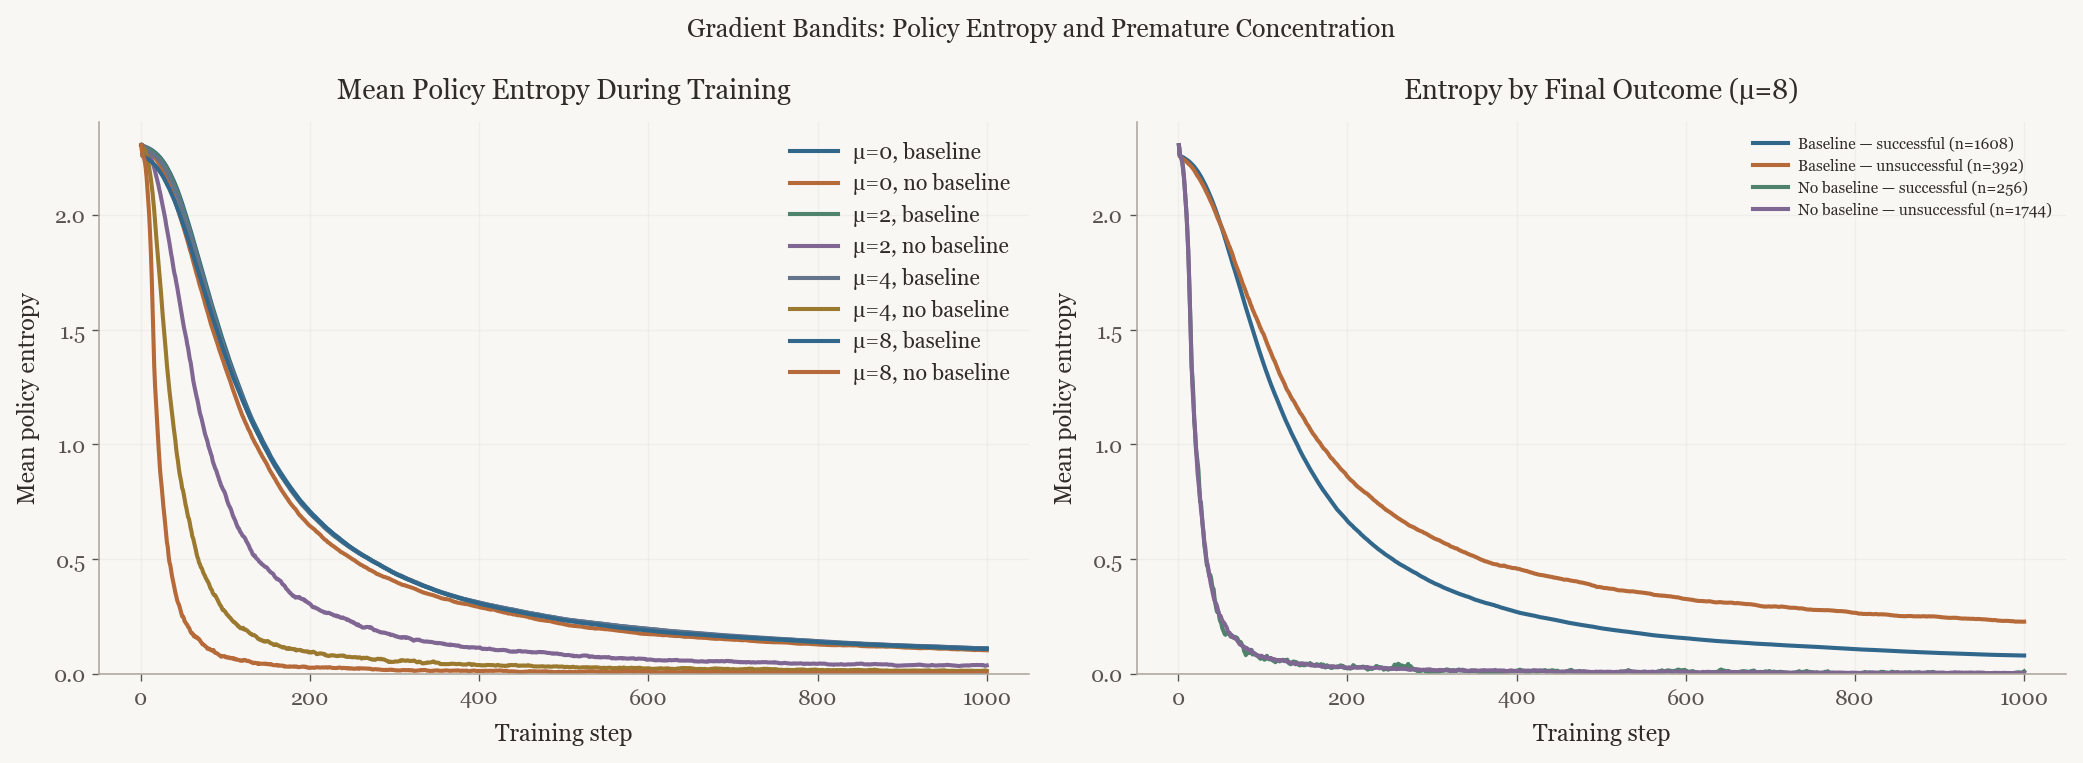

In [21]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 5.5)
)

steps = np.arange(1, num_steps + 1)

ax = axes[0]

for (mu, use_baseline), result in results.items():
    mean_entropy = np.mean(
        result["entropies"], axis=0
    )

    label = (
        f"μ={mu:g}, "
        f"{'baseline' if use_baseline else 'no baseline'}"
    )

    ax.plot(
        steps,
        mean_entropy,
        label=label,
    )

ax.set_xlabel("Training step")
ax.set_ylabel("Mean policy entropy")
ax.set_title("Mean Policy Entropy During Training")
ax.set_ylim(0, np.log(k) + 0.1)
ax.grid(alpha=0.3)
ax.legend()


ax = axes[1]
mu = 8.0

for use_baseline in baseline_options:
    result = results[(mu, use_baseline)]

    entropies = result["entropies"]
    successful = result["successful"]

    for is_success, status in [
        (True, "successful"),
        (False, "unsuccessful"),
    ]:
        mask = successful == is_success
        count = np.sum(mask)

        if count == 0:
            continue

        mean_entropy = np.mean(
            entropies[mask],
            axis=0,
        )

        label = (
            f"{'Baseline' if use_baseline else 'No baseline'}"
            f" — {status} (n={count})"
        )

        ax.plot(
            steps,
            mean_entropy,
            label=label,
        )

ax.set_xlabel("Training step")
ax.set_ylabel("Mean policy entropy")
ax.set_title("Entropy by Final Outcome (μ=8)")
ax.set_ylim(0, np.log(k) + 0.1)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.suptitle(
    "Gradient Bandits: Policy Entropy and Premature Concentration",
    fontsize=13,
)

plt.tight_layout()
plt.show()

The left plot shows that policy entropy falls much faster without a baseline, while the baseline agent maintains a more spread-out policy for longer. The right plot shows a similar pattern in both successful and unsuccessful runs. The no-baseline agent concentrates its policy quickly, regardless of whether it has selected the optimal action.

## Premature Policy Concentration and Recovery

A low-entropy policy is not necessarily a problem. In fact, if the agent has identified the best arm, we want it to select that arm most of the time. The problem occurs when the policy becomes highly concentrated on a suboptimal action early in training.

### How Softmax Concentration Affects Exploration

Recall that the softmax policy converts action preferences into probabilities:

$$
\pi(a)=\frac{\exp(H(a))}{\sum_b\exp(H(b))}
$$

For any two actions $a_1$ and $a_2$, their probability ratio is:

$$
\frac{\pi(a_1)}{\pi(a_2)}=\exp(H(a_1)-H(a_2))
$$

This means small differences in preferences can produce large differences in selection probabilities. If one action's preference is greater than another's by $5$, it is about 148 times as likely to be selected. If the difference is $10$, it is about 22,026 times as likely.

A few large stochastic updates can therefore make one action dominate the policy. However, the policy has no way of knowing whether that action is actually optimal. It simply reflects the preferences learned so far.

### Why Recovery Becomes Slow

Recall the preference update with a baseline:

$$
H_{t+1}(a)=H_t(a)+\alpha(R_t-b_t)\left(\mathbb{1}[a=A_t]-\pi_t(a)\right)
$$

Suppose the policy has become concentrated on a suboptimal action $a_s$:

$$
\pi_t(a_s)\approx1
$$

There are two reasons why it can take a long time to recover.

First, the alternative actions are rarely sampled. If the probability of selecting the optimal action $a^*$ is very small, the agent may take many steps before trying it again. For a fixed selection probability $p$, the expected number of trials before the action is selected is:

$$
\mathbb{E}[T]=\frac{1}{p}
$$

For example, if an action has probability $0.001$, we would expect to wait 1,000 steps before selecting it, assuming that probability remains fixed.

Second, the preference updates themselves become small. When the dominant action is selected, its update is:

$$
\Delta H(a_s)=\alpha(R_t-b_t)(1-\pi_t(a_s))
$$

As $\pi_t(a_s)$ approaches $1$, the factor $1-\pi_t(a_s)$ approaches zero. For an action $a$ that was not selected, the update is:

$$
\Delta H(a)=-\alpha(R_t-b_t)\pi_t(a)
$$

If that action has a very small selection probability, its update will also be small. The agent therefore enters a regime in which it repeatedly selects the dominant action, rarely explores the alternatives, and makes only small preference updates on most steps.

This creates a feedback loop. The current policy determines which actions are sampled, and those samples determine how the policy is updated.

### Connecting This to Our Experiments

We can now connect our results. Increasing the common reward offset increased gradient variance for the agent without a baseline, despite leaving the expected gradient unchanged. The larger stochastic updates were accompanied by a much faster reduction in policy entropy.

At $\mu=8$, the no-baseline agent's entropy fell rapidly within roughly the first 100 steps, both in runs that eventually succeeded and in runs that failed. This tells us that rapid policy concentration is not the same as learning the optimal action. In many runs, the agent became highly confident in an action before it had gathered enough evidence to determine whether that action was optimal.

Once a suboptimal action dominated the policy, the dynamics described above made it difficult to recover within our 1,000-step training horizon. Subtracting the running-average reward reduced the effect of the common offset, leading to more gradual policy concentration and better optimal-action selection in our experiments.

### Does Premature Concentration Mean Permanent Failure?

Not necessarily. As long as the action preferences are finite, softmax assigns a positive probability to every action. A suboptimal action does not become permanently inaccessible simply because the policy strongly favors another action.

However, the probability of sampling an alternative can become so small that recovery takes much longer than the training horizon. Our experiments therefore demonstrate a finite-horizon learning problem, not permanent convergence to a suboptimal policy.

The broader point is that two gradient estimators with the same expectation can produce very different learning trajectories. In our experiments, subtracting a reward baseline reduced gradient variance, slowed premature policy concentration, and made the agent much more likely to identify and consistently select the optimal action.

<script src="https://utteranc.es/client.js"
        repo="novastar53/novastar53.github.io"
        issue-term="pathname"
        theme="github-light"
        crossorigin="anonymous"
        async>
</script>